In [71]:
import torch
import torch.nn.functional as F
import torchmetrics

import lightning as L

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

from tests import test_category_embedder, test_house_price_regressor, print_dataset_info

B1. Data
---

a. Load the dataset using pandas

b. Create train, test and validation splits

c. Encode categorical features

d. Scale continuous features

e. Implement a PyTorch dataset

f. Create PyTorch dataloaders

### B1(a) Load the data using pandas

In [72]:
# data = ... TODO

# define the continuous and categorical columns
import pandas as pd

continuous_cols = [
    "dist_to_nearest_stn",
    "dist_to_dhoby",
    "degree_centrality",
    "eigenvector_centrality",
    "remaining_lease_years",
    "floor_area_sqm",
]

categorical_cols = ["month", "town", "flat_model_type", "storey_range"]

df = pd.read_csv(r".\hdb_price_prediction.csv")

### B1(b) Temporal split with validation

Create a temporal split:

1.	Train/Val pool: all rows with year <= 2020.

2.	From this pool, randomly sample 10% of the dataset to create a validation set.

3.	Test set: all rows with year == 2021.

4.	Print shapes (n_rows, n_cols) for train_data, val_data, test_data.

In [73]:
# train_data, val_data, test_data = ... TODO
from sklearn.model_selection import train_test_split
nd_test = test_data = df[df["year"] == 2021].to_numpy()
nd_train_val = df[df["year"] <= 2020].to_numpy()
nd_train, nd_val = train_data, val_data = train_test_split(nd_train_val, test_size = int(.1 * nd_train_val.shape[0]), shuffle= True, random_state=0)

In [74]:
# DO NOT MODIFY
train_data.shape, val_data.shape, test_data.shape

((78633, 14), (8737, 14), (29057, 14))

### B1(c) Encode categorical features w/o leakage

1.	Create an `sklearn.preprocessing.OrdinalEncoder` with handle_unknown="use_encoded_value", unknown_value=-1.

2.	Fit on train_data[categorical_cols] only.

3.	Transform val_data and test_data using the fitted encoder.

4. Compute and print the cardinality (number of distinct codes) for each categorical column on train_data after encoding. (These will be used to define embedding tables later.)

### B1(d) Scale continuous features w/o leakage

1.	Create a `StandardScaler`.

2.	Fit on train_data[continuous_cols] only.

3.	Transform val_data and test_data.

4.	Report the mean and std of each continuous feature on the transformed train split (they should be ~0 and ~1).

Do not scale resale_price.

In [ ]:
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

ord_encoder = oe = OrdinalEncoder(handle_unknown= "use_encoded_value", unknown_value= -1)
categorical_idxs = [df.columns.get_loc(col) for col in categorical_cols]
nd_train_data_categorical = ord_encoder.fit_transform(train_data[:, categorical_idxs])
nd_val_data_categorical = ord_encoder.transform(val_data[:, categorical_idxs])
nd_test_data_categorical = ord_encoder.transform(test_data[:, categorical_idxs])

print("Learned categories per categorical feature:")
for i, categories in enumerate(ord_encoder.categories_):
    print(f"\nFeature {i}, {categorical_cols[i]} ({len(categories)} categories): \n{categories}")

std_encoder = StandardScaler()
continuous_idxs = [df.columns.get_loc(col) for col in continuous_cols]
nd_train_data_continuous = std_encoder.fit_transform(train_data[:, continuous_idxs])
nd_val_data_continuous = std_encoder.transform(val_data[:, continuous_idxs])
nd_test_data_continuous = std_encoder.transform(test_data[:, continuous_idxs])

print("\nLearned mean and std per continuous feature:")
stats_df = pd.DataFrame({
    "Feature": continuous_cols,
    "Mean": std_encoder.mean_,
    "Standard Deviation": std_encoder.scale_
})
display(stats_df)

other_idxs = [i for i in range(df.shape[1]) if i not in categorical_idxs and i not in continuous_idxs]
train_data = nd_train = np.concatenate([nd_train_data_categorical, nd_train_data_continuous, train_data[:, other_idxs]], axis=1)
val_data = nd_val = np.concatenate([nd_val_data_categorical, nd_val_data_continuous, val_data[:, other_idxs]], axis=1)
test_data = nd_test = np.concatenate([nd_test_data_categorical, nd_test_data_continuous, test_data[:, other_idxs]], axis=1)


Learned categories per categorical feature:

Feature 0, month (12 categories): 
[1 2 3 4 5 6 7 8 9 10 11 12]

Feature 1, town (26 categories): 
['ANG MO KIO' 'BEDOK' 'BISHAN' 'BUKIT BATOK' 'BUKIT MERAH' 'BUKIT PANJANG'
 'BUKIT TIMAH' 'CENTRAL AREA' 'CHOA CHU KANG' 'CLEMENTI' 'GEYLANG'
 'HOUGANG' 'JURONG EAST' 'JURONG WEST' 'KALLANG/WHAMPOA' 'MARINE PARADE'
 'PASIR RIS' 'PUNGGOL' 'QUEENSTOWN' 'SEMBAWANG' 'SENGKANG' 'SERANGOON'
 'TAMPINES' 'TOA PAYOH' 'WOODLANDS' 'YISHUN']

Feature 2, flat_model_type (43 categories): 
['1 ROOM, Improved' '2 ROOM, 2-room' '2 ROOM, DBSS' '2 ROOM, Improved'
 '2 ROOM, Model A' '2 ROOM, Premium Apartment' '2 ROOM, Standard'
 '3 ROOM, DBSS' '3 ROOM, Improved' '3 ROOM, Model A'
 '3 ROOM, New Generation' '3 ROOM, Premium Apartment' '3 ROOM, Simplified'
 '3 ROOM, Standard' '3 ROOM, Terrace' '4 ROOM, Adjoined flat'
 '4 ROOM, DBSS' '4 ROOM, Improved' '4 ROOM, Model A' '4 ROOM, Model A2'
 '4 ROOM, New Generation' '4 ROOM, Premium Apartment'
 '4 ROOM, Premium Apartme

,Feature,Mean,Standard Deviation
0,dist_to_nearest_stn,0.812527,0.466529
1,dist_to_dhoby,11.222147,4.178087
2,degree_centrality,0.017469,0.004822
3,eigenvector_centrality,0.006570,0.020864
4,remaining_lease_years,74.757237,12.964883
5,floor_area_sqm,97.717681,24.256286


In [76]:
# DO NOT MODIFY
train_data.shape, val_data.shape, test_data.shape

((78633, 14), (8737, 14), (29057, 14))

In [77]:
display(pd.DataFrame(train_data))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,0.0,1.0,10.0,2.0,-1.113467,-0.470925,-0.137284,-0.281472,-1.151102,-1.225154,2020,703 BEDOK RESERVOIR ROAD,Bedok North,300000.0
1,3.0,11.0,31.0,3.0,-0.521984,-0.451148,-0.137284,-0.242676,-0.759017,1.49579,2017,306 HOUGANG AVENUE 5,Hougang,525000.0
2,1.0,5.0,33.0,3.0,0.341423,0.578461,-1.880103,-0.31156,0.847888,0.506356,2018,629 SENJA ROAD,Bukit Panjang,438000.0
3,11.0,20.0,33.0,4.0,0.647706,-0.040134,-0.137284,-0.303728,0.712908,0.547583,2017,309D ANCHORVALE ROAD,Sengkang,412000.0
4,7.0,12.0,29.0,2.0,-0.434859,0.350796,1.605536,-0.288576,-0.881142,0.91862,2018,103 JURONG EAST STREET 13,Jurong East,620000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78628,0.0,23.0,18.0,0.0,0.468845,-1.793761,-0.137284,1.455785,-0.366933,0.423903,2018,245 KIM KEAT LINK,Toa Payoh,475000.0
78629,2.0,20.0,21.0,4.0,0.101434,0.101034,-0.137284,-0.303728,1.567781,-0.23572,2019,327A ANCHORVALE ROAD,Sengkang,455000.0
78630,0.0,13.0,33.0,0.0,-0.634903,1.18853,-0.137284,-0.313306,0.262974,1.0423,2019,694 JURONG WEST CENTRAL 1,Boon Lay,465000.0
78631,1.0,1.0,35.0,3.0,0.438246,-0.024013,1.605536,-0.286787,-1.31822,1.0423,2019,66 BEDOK SOUTH AVENUE 3,Tanah Merah,563000.0


### B1(e) Implement a PyTorch Dataset

Implement HDBPriceDataset(Dataset) with:
- `__init__(self, data, categorical_cols, continuous_cols, target_col="resale_price")`

- `__getitem__(idx)` returns a dict: {"x_cat": LongTensor, "x_cont": FloatTensor, "y": FloatTensor}

In [78]:
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split

class HDBPriceDataset(Dataset):
    def __init__(self, data : np.ndarray, categorical_cols, continuous_cols, target_col = "resale_price") -> None:
        super().__init__()
        self.data = data
        self.categorical_cols = categorical_cols
        self.continuous_cols = continuous_cols
        self.target_col = target_col
        
        # depends on the train_data and val_data and test_data append categorical before continuous before other
        self.categorical_idxs = range(0, len(categorical_cols))
        self.continuous_idxs = range(len(categorical_cols), len(categorical_cols) + len(continuous_cols))
        self.other_idxs = range(len(categorical_cols) + len(continuous_cols), data.shape[1])
        # depends on the global variable df
        self.target_idx = df.columns.get_loc(target_col)
        self.t_x_cat = torch.tensor(self.data[:, self.categorical_idxs].astype(int), dtype= torch.long)
        self.t_x_cont = torch.tensor(self.data[:, self.continuous_idxs].astype(float), dtype= torch.float)
        self.t_y = torch.tensor(self.data[:, self.target_idx].astype(int), dtype = torch.float)
    def __getitem__(self, idx):
        return {"x_cat" : self.t_x_cat[idx], "x_cont" : self.t_x_cont[idx], "y" : self.t_y[idx]}
    
    def __len__(self):
        return self.data.shape[0]

### B1(f) Create train, validation and test data loaders

Create train, validation and test datasets and data loaders. Use a batch size of 1024

In [ ]:
batch_size = 1024

train_dataset, val_dataset, test_dataset = HDBPriceDataset(train_data, categorical_cols, continuous_cols), HDBPriceDataset(val_data, categorical_cols, continuous_cols), HDBPriceDataset(test_data, categorical_cols, continuous_cols)

train_loader, val_loader, test_loader = DataLoader(train_dataset, batch_size=1024, num_workers= 11), DataLoader(val_dataset, batch_size=1024, num_workers= 11), DataLoader(test_dataset, batch_size=1024, num_workers= 11)

In [80]:
# DO NOT MODIFY
print_dataset_info(train_dataset, test_dataset, train_loader, test_loader)

Dataset info:
Train samples: 78,633
Test samples: 29,057
Total batches (train): 77
Total batches (test): 29

Sample batch shapes:
Categorical: torch.Size([1024, 4])
Continuous: torch.Size([1024, 6])
Target: torch.Size([1024])


B2. Model and training
---
a. Create a PyTorch Model

b. Write a LightningModule for fitting the model

c. Train the model

d. Predict using the trained model on the test set and calculate $R^2$

### B2(a) Create a PyTorch Model

In this part you will build a PyTorch model for tabular house-price regression that (i) embeds each categorical feature into a dense vector, (ii) concatenates all category embeddings with the standardized continuous features, and (iii) predicts resale_price via a small MLP.

You must implement two modules:
1.	CategoryEmbedder — one embedding table per categorical column plus optional dropout.

2.	HousePriceRegressor — uses CategoryEmbedder, concatenates with continuous features, then a 3-layer MLP.

You will then instantiate the model using provided cardinalities and embedding dimensions.

Use the same feature schema and encoded/scaled splits you produced in Part 1. Assume you already have train_loader, val_loader, test_loader, continuous_cols, oe (the fitted OrdinalEncoder), and batch_size.

A. Implement CategoryEmbedder (10 pts)

Create a module that receives:
- cardinalities: List[int] — number of distinct codes per categorical column (from oe.categories_).

- embed_dims: List[int] — embedding dimension for each categorical column (same length as cardinalities).

- emb_dropout: float — dropout applied after concatenation of all embeddings.

Requirements

1.	Construct a nn.ModuleList of nn.Embedding(num_embeddings=c, embedding_dim=d) for each (c, d) pair.

2.	In forward(x_cat), where x_cat has shape [B, C] (C = #categorical columns):

	- Look up each column i using its table: emb_i(x_cat[:, i]) → [B, d_i].

	- Concatenate along feature dimension → [B, sum(embed_dims)].

	- Apply Dropout(emb_dropout) and return.

In [81]:
import torch.nn as nn
from typing import List
import torch.nn.functional as F

class CategoryEmbedder(nn.Module):
    def __init__(self, cardinalities: List[int], embed_dims: List[int], emb_dropout: float =0.0):
        """Initialize the CategoryEmbedder.
        Args:
            cardinalities (list): List of integers representing the number of unique values for each categorical feature.
            embedding_dims (list): List of integers representing the embedding dimensions for each categorical feature.
            embed_dropout (float): Dropout rate for the embeddings.
        """
        super().__init__()
        # self.embed_list = nn.ModuleList(nn.Embedding(num_embeddings=cardinalities, embedding_dim= embed_dims))
        self.embed_list = nn.ModuleList([
            nn.Embedding(num_embeddings=cardinality, embedding_dim=embed_dim)
            for cardinality, embed_dim in zip(cardinalities, embed_dims)
        ])
        self.emb_dropout = emb_dropout

    def forward(self, x_cat: torch.Tensor):
        embs = [emb(x_cat[:, i]) for i, emb in enumerate(self.embed_list)]
        x = torch.cat(embs, dim = 1)
        x = F.dropout(x, p = self.emb_dropout)
        
        return x

In [82]:
test_category_embedder(CategoryEmbedder)

Test 1: Basic functionality
Input shape: torch.Size([32, 3])
Output shape: torch.Size([32, 14])
Expected output dim: 14
✓ Basic functionality test passed

Test 2: Single categorical feature
✓ Single feature test passed

Test 3: Edge case with minimum values
✓ Minimum values test passed

All tests passed! 🎉


In [83]:
class HousePriceRegressor(nn.Module):
    def __init__(self, cardinalities, embed_dims, n_continuous, emb_dropout=0.0):
        """Initialize the HousePriceRegressor.

        Args:
            cardinalities (list): List of integers representing the number of unique values for each categorical feature.
            embed_dims (list): List of integers representing the embedding dimensions for each categorical feature.
            n_continuous (int): Number of continuous features.
            emb_dropout (float, optional): Dropout rate for the embeddings. Defaults to 0.0.
        """
        super().__init__()
        self.cardinalities = cardinalities
        self.embed_dims = embed_dims
        self.n_continuous = n_continuous
        self.emb_dropout = emb_dropout
        self.cat_embedder = CategoryEmbedder(cardinalities,embed_dims, emb_dropout)
        
        current_input_size = sum(embed_dims) + n_continuous
        width = [current_input_size, current_input_size, current_input_size, 1]
        # width = [current_input_size, int(current_input_size/2), int(current_input_size / 4), 1]
        self.mlp_stack = nn.Sequential(
            nn.Linear(width[0], width[1]),
            nn.ReLU(),
            # nn.Dropout(),
            nn.Linear(width[1], width[2]),
            nn.ReLU(),
            # nn.Dropout(),
            nn.Linear(width[2], width[3]),
        )

    def forward(self, x_cat, x_cont):
        x_cat = self.cat_embedder(x_cat)
        x_cat_cont = torch.concat((x_cat, x_cont), dim = 1)
        return self.mlp_stack(x_cat_cont).flatten()

In [84]:
# DO NOT MODIFY
test_house_price_regressor(HousePriceRegressor)

Testing HousePriceRegressor...
Categorical input shape: torch.Size([32, 4])
Continuous input shape: torch.Size([32, 6])
Output shape: torch.Size([32])
Output type: torch.float32
Sample predictions: [0.12493933737277985, 0.033496707677841187, 0.09186340868473053, -0.03296668082475662, 0.07535642385482788]
✓ Basic functionality test passed
✓ Batch size 1 test passed
✓ Batch size 16 test passed
✓ Batch size 64 test passed
✓ Batch size 128 test passed

Model info:
Total parameters: 3,583
Trainable parameters: 3,583

All HousePriceRegressor tests passed! 🎉


In [85]:
# DO NOT MODIFY
cardinalities = [len(categories) for categories in oe.categories_]
embedding_dims = [min(50, (c + 1) // 2) for c in cardinalities]
n_continuous = len(continuous_cols)

# Create model with proper cardinalities
model = HousePriceRegressor(
    cardinalities=cardinalities,
    embed_dims=embedding_dims,
    n_continuous=n_continuous,
    emb_dropout=0.1,
)

### B2(b) PyTorch LightningModule

Wrap your HousePriceRegressor into a PyTorch LightningModule so that training, validation, and testing are managed automatically.

What to do

1.	Initialize the module
    - Store hyperparameters (embedding sizes, number of continuous features, learning rate, etc.).

    - Create an instance of your HousePriceRegressor.

    - Choose a suitable regression loss function (e.g., MSE).

    - Set up at least one evaluation metric (e.g., MAE, RMSE).

2.	Forward method
    - Define a forward pass that takes categorical + continuous features and returns predictions.

3.	Training, Validation, and Test steps
    - In each step:
        - Extract features and target from the batch.

        - Run the model forward.

        - Compute the loss.

        - Log the loss and chosen metrics so they can be monitored.

4.	Prediction step
    - Implement a method to return predictions on new data without computing loss.

5.	Optimiser
    - Use a suitable optimiser (e.g., Adam) with a reasonable learning rate.

    - (Optional: add a scheduler if you wish to experiment.)

In [ ]:
class HDBPriceLightningModule(L.LightningModule):
	def __init__(
		self,
		cardinalities,
		embedding_dims,
		n_continuous,
		emb_dropout=0.0,
		learning_rate=0.1
	):
		super().__init__()
		self.save_hyperparameters()

		self.model = HousePriceRegressor(
			cardinalities=cardinalities,
			embed_dims=embedding_dims,
			n_continuous=n_continuous,
			emb_dropout=emb_dropout
		)

		self.loss_fn = nn.MSELoss()
		# torch metrics stateful, cant treat as a function which is refreshed every time its run, treat as object 
		self.train_mae = torchmetrics.MeanAbsoluteError()
		self.val_mae = torchmetrics.MeanAbsoluteError()
		self.test_mae = torchmetrics.MeanAbsoluteError()
		# I am addicted to percentages, MAPE outputs easier to compare how wrong the models are 
		self.train_mape = torchmetrics.MeanAbsolutePercentageError()
		self.val_mape = torchmetrics.MeanAbsolutePercentageError()
		self.test_mape = torchmetrics.MeanAbsolutePercentageError()

	def forward(self, x_cat, x_cont):
		return self.model(x_cat, x_cont)

	# --- Training Step ---
	def training_step(self, batch, batch_idx):
		x_cat, x_cont, y = batch["x_cat"], batch["x_cont"], batch["y"]
		y_pred = self.forward(x_cat, x_cont)
		loss = self.loss_fn(y_pred, y)

		# Compute MAE
		mae = self.train_mae(y_pred, y)

		# Compute MAPE
		mape = self.train_mape(y_pred, y)

		# Log both
		self.log("train_loss", loss, prog_bar=True)
		self.log("train_mae", mae, prog_bar=True)
		self.log("train_mape", mape, prog_bar=True)

		return loss

	# --- Validation Step ---
	def validation_step(self, batch, batch_idx):
		x_cat, x_cont, y = batch["x_cat"], batch["x_cont"], batch["y"]
		y_pred = self.forward(x_cat, x_cont)
		loss = self.loss_fn(y_pred, y)
		mae = self.val_mae(y_pred, y)
		mape = self.val_mape(y_pred, y)

		self.log("val_loss", loss, prog_bar=True)
		self.log("val_mae", mae, prog_bar=True)
		self.log("val_mape", mape, prog_bar=True)

	# --- Test Step ---
	def test_step(self, batch, batch_idx):
		x_cat, x_cont, y = batch["x_cat"], batch["x_cont"], batch["y"]
		y_pred = self.forward(x_cat, x_cont)
		loss = self.loss_fn(y_pred, y)
		mae = self.test_mae(y_pred, y)
		mape = self.test_mape(y_pred, y)

		self.log("test_loss", loss)
		self.log("test_mae", mae)
		self.log("test_mape", mape)

	# --- Prediction Step ---
	def predict_step(self, batch, batch_idx, dataloader_idx=0):
		x_cat, x_cont, y = batch["x_cat"], batch["x_cont"], batch["y"]
		return self.forward(x_cat, x_cont)

	# --- Optimizer ---
	def configure_optimizers(self):
		optimizer = torch.optim.Adam(self.parameters(), lr=self.hparams.learning_rate)

		# Optional scheduler for extra credit
		scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
			optimizer, mode="min", factor=0.5, patience=3
		)

		return {
			"optimizer": optimizer,
			"lr_scheduler": {
				"scheduler": scheduler,
				"monitor": "val_loss"
			}
		}


In [87]:
# DO NOT MODIFY
lightning_model = HDBPriceLightningModule(
    cardinalities=cardinalities,
    embedding_dims=embedding_dims,
    n_continuous=n_continuous,
    emb_dropout=0.1,
)

### B2(c) Train the model

What to do
1.	Checkpoints
    - Add a checkpoint callback that monitors validation loss and keeps the best models (e.g., top-k) plus the last checkpoint for resuming.

2.	Early stopping
    - Add early stopping on the same validation metric with a reasonable patience and a small min_delta (use a tiny positive value to require real improvement).

3.	Learning-rate tracking
    - Log the learning rate each epoch/step with a LR monitor so it’s visible in your logger.

4.	Experiment logging
    - Create a logger (e.g., TensorBoard) with a clear experiment name and save directory.

5.	Trainer configuration
    - Set a sensible number of epochs, devices/accelerator (CPU/GPU), and enable gradient clipping.

    - Turn on progress bar and model summary for visibility.

    - Choose an appropriate logging frequency for your dataset size.

6.	Fit & Test
- Call trainer.fit(model, train_loader, val_loader).

- Optionally run trainer.test(model, test_loader) after training and print metrics.

7. Download the plots for validation loss, your validation metric and display it.

In [ ]:
max_epochs = 50

import lightning as L
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor
from lightning.pytorch.loggers import TensorBoardLogger


# --- 1. Checkpoints ---
checkpoint_callback = ModelCheckpoint(
	monitor="val_loss",        # what to monitor
	mode="min",                # minimize validation loss
	save_top_k=3,              # keep best 3 models
	save_last=True,            # also save last checkpoint
	filename="houseprice-{epoch:02d}-{val_loss:.4f}",  # naming format
	verbose=True
)

# --- 2. Early Stopping ---
early_stop_callback = EarlyStopping(
	monitor="val_loss",
	mode="min",
	patience=5,                # stop if no improvement for 5 epochs
	min_delta=1e-4,            # minimum improvement to reset patience counter
	verbose=True
)

# --- 3. Learning Rate Tracking ---
lr_monitor = LearningRateMonitor(logging_interval="epoch")

# --- 4. Experiment Logging ---
logger = TensorBoardLogger(
	save_dir="lightning_logs",
	name="HousePriceExperiment"
)

# --- 5. Trainer Configuration --
trainer = L.Trainer(
	max_epochs=max_epochs,
	accelerator="auto",            
	devices=1,
	logger=logger,
	callbacks=[checkpoint_callback, early_stop_callback, lr_monitor],
	gradient_clip_val=1.0,         # prevent exploding gradients
	log_every_n_steps=10,          # log every 10 batches
	enable_progress_bar=True,
	enable_model_summary=True
)

# --- 6. Fit & Test ---
trainer.fit(lightning_model, train_loader, val_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



  | Name       | Type                        | Params | Mode 
-------------------------------------------------------------------
0 | model      | HousePriceRegressor         | 8.0 K  | train
1 | loss_fn    | MSELoss                     | 0      | train
2 | train_mae  | MeanAbsoluteError           | 0      | train
3 | val_mae    | MeanAbsoluteError           | 0      | train
4 | test_mae   | MeanAbsoluteError           | 0      | train
5 | train_mape | MeanAbsolutePercentageError | 0      | train
6 | val_mape   | MeanAbsolutePercentageError | 0      | train
7 | test_mape  | MeanAbsolutePercentageError | 0      | train
-------------------------------------------------------------------
8.0 K     Trainable params
0         Non-trainable params
8.0 K     Total params
0.032     Total estimated model params size (MB)
20        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

c:\Users\kyeyo\venvs\jupyterVenv15Oct2024\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:433: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.
c:\Users\kyeyo\venvs\jupyterVenv15Oct2024\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:433: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 49, global step 3850: 'val_loss' was not in top 3
`Trainer.fit` stopped: `max_epochs=50` reached.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\kyeyo\venvs\jupyterVenv15Oct2024\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:433: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_loss         │       4274800640.0        │
│         test_mae          │      54560.82421875       │
│         test_mape         │    0.10737466812133789    │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 4274800640.0,
  'test_mae': 54560.82421875,
  'test_mape': 0.10737466812133789}]

### B2(d) Model prediction and evaluation

1.	Run prediction
    - Use trainer.predict(model, test_loader) to generate predictions on the held-out test set.

    - Concatenate predictions into a single tensor/array.

2. Report results
    - Print R² (rounded to 4 decimal places).

    - Interpret the value of R² briefly

In [ ]:
predictions = trainer.predict(lightning_model, test_loader)

predictions = torch.concat(predictions, dim=0)

# Get ground-truth targets from the test loader
y_true_list = []
for batch in test_loader:
    y_true_list.append(batch["y"])
y_true = torch.cat(y_true_list, dim=0)

r2 = r2_score(predictions, y_true)
print(f"R² on test set: {r2:.4f}")

if r2<0:
    print("r2 < 0, model is worse than mean predictor")
if r2>0:
    print("r2 > 0, model is better than mean predictor")
print(f"Model explains {100 * r2:.2f} % of the variance in house prices")
# print(f"R^2 on test set =")

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\kyeyo\venvs\jupyterVenv15Oct2024\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:433: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

R² on test set: 0.8150
r2 > 0, model is better than mean predictor
Model explains 81.50% of the variance in house prices


B3. Model Interpretability with Integrated Gradients
---

 What to do
1.	Choose an explainability method

    - Use Integrated Gradients (IG) from captum.attr.

    - Treat the continuous features (x_cont) as the primary inputs for attribution.

    - Pass categorical features (x_cat) as additional arguments to the forward function.

2.	Define a forward wrapper

    - Implement a wrapper function so IG knows how to call your model with both categorical and continuous features.

3.	Local explanation (per sample)

    - Run IG on a single batch from the training set.

    - Use a zero baseline for continuous features.

    - Plot the continuous features ranked by signed contribution for one example.

4.	Global explanation (across dataset)

    - Loop over the validation set to compute mean absolute attributions for each continuous feature.

    - Normalize by the number of samples.

    - Rank features by importance and plot a bar chart showing the most influential features globally.

5.	Interpret results

    - Report which features matter most for the model’s predictions.

    - Reflect briefly: Do these align with intuition (e.g., distance to station, floor area)?

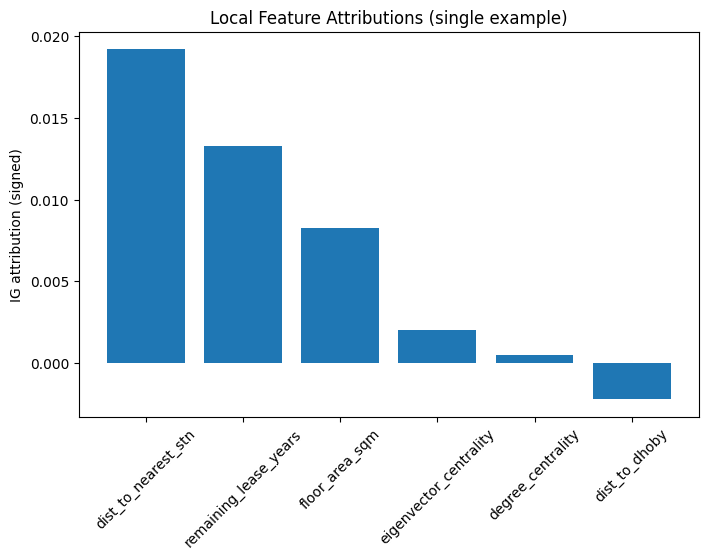

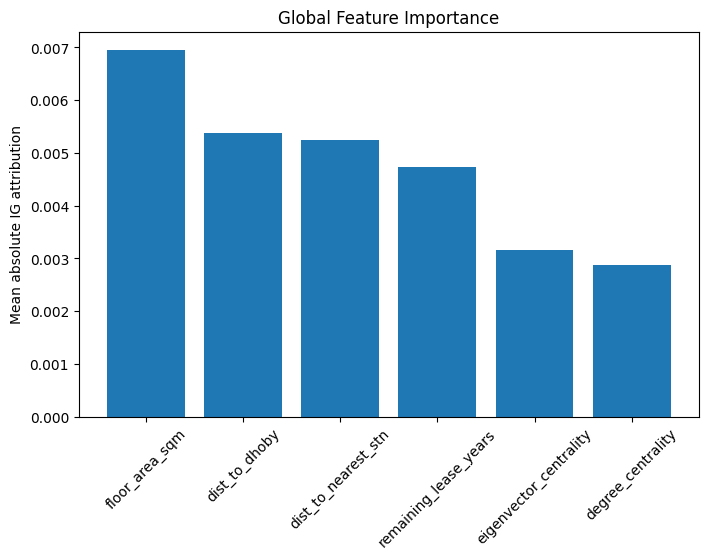

In [ ]:
from captum.attr import IntegratedGradients

lightning_model.eval()

def forward_cont(x_cont, x_cat):
    """
    Forward wrapper for IG:
    - x_cont: tensor of continuous features (primary input)
    - x_cat: tensor of categorical features (additional args)
    Returns predicted value (scalar per sample)
    """
    return model(x_cat, x_cont)

# Take one batch from training set
def extract_3_tuple(dataloader : DataLoader):
    batch = next(iter(dataloader))
    yield batch["x_cat"], batch["x_cont"], batch["y"]

x_cat_batch, x_cont_batch, y_batch = next(extract_3_tuple(train_loader))

# Select one example
x_cat_example = x_cat_batch[0].unsqueeze(0)
x_cont_example = x_cont_batch[0].unsqueeze(0)

# Create baseline (all zeros for continuous features)
baseline = torch.zeros_like(x_cont_example)

# Initialize Integrated Gradients
ig = IntegratedGradients(forward_cont)

# Compute attributions
attributions, delta = ig.attribute(
    x_cont_example,
    baselines=baseline,
    additional_forward_args=(x_cat_example,),
    return_convergence_delta=True
)

# Convert to numpy
attr_values = attributions.detach().numpy().flatten()
feature_names = continuous_cols  # list of continuous feature names

# Rank features by signed contribution
sorted_idx = attr_values.argsort()[::-1]

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar([feature_names[i] for i in sorted_idx], attr_values[sorted_idx])
plt.xticks(rotation=45)
plt.ylabel("IG attribution (signed)")
plt.title("Local Feature Attributions (single example)")
plt.show()


import numpy as np

global_attr = np.zeros(len(continuous_cols))
num_samples = 0

for x_cat_batch, x_cont_batch, y_batch in extract_3_tuple(val_loader):
    baseline_batch = torch.zeros_like(x_cont_batch)
    attributions = ig.attribute(
        x_cont_batch,
        baselines=baseline_batch,
        additional_forward_args=(x_cat_batch,)
    )
    global_attr += attributions.abs().sum(dim=0).detach().numpy()
    num_samples += x_cont_batch.shape[0]

# Average over all samples
global_attr /= num_samples

# Rank features by importance
sorted_idx = global_attr.argsort()[::-1]

plt.figure(figsize=(8,5))
plt.bar([continuous_cols[i] for i in sorted_idx], global_attr[sorted_idx])
plt.xticks(rotation=45)
plt.ylabel("Mean absolute IG attribution")
plt.title("Global Feature Importance")
plt.show()

print("""
The features that matter the most are:

""")